# Ingredient Scanner: the NLP behind it

Every NLP concept the project uses, in the order the app uses them. Each section has a one-paragraph
explanation, a small piece of code that calls the project's **real** modules (`src/...`), and the
results: live checks on small samples (seconds) and the saved results of the long training runs.

| # | Section | NLP syllabus |
|---|---|---|
| 1 | Dataset and corpus | corpora, text corpus structure |
| 2 | Preprocessing: normalisation, tokenisation, regular expressions, sub-words | Unit 2, Unit 3 (regex) |
| 3 | Weak supervision and BIO tagging | annotated corpora, chunking |
| 4 | Named entity recognition: rules vs CRF vs DistilBERT | Unit 4 (rule-based, stochastic, ML tagging, NER) |
| 5 | Evaluation: precision, recall, F1, noise robustness, error analysis | evaluation |
| 6 | Spelling correction and edit distance | lexical similarity |
| 7 | OCR quality: character and word error rate (CER, WER) | evaluation |
| 8 | N-gram language model, smoothing and perplexity | Unit 3 (n-grams, smoothing) |
| 9 | Entity linking, synonymy, fuzzy matching | Unit 5 (lexical relations) |
| 10 | Text representations: BoW, TF-IDF, cosine / Jaccard / Euclidean / Manhattan | Unit 2 |
| 11 | Word embeddings: ingredient2vec (word2vec) | Unit 5 (distributional semantics, word2vec) |
| 12 | Base paper and extension: noise-aware training (NAT) | research paper |
| 13 | The ingredient assistant: intents, entities, reference resolution, QA | Units 6-7 |
| 14 | Summary of results | |

Run from top to bottom (about 3-5 minutes on a laptop CPU).

## 0. Setup

In [1]:
import os, sys, json, re, warnings
from collections import Counter
from pathlib import Path
os.environ["USE_TF"] = "0"          # this laptop's global Python has a broken TensorFlow; transformers must skip it
os.environ["USE_TORCH"] = "1"
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(path, width=760):
    display(Image(filename=str(ROOT / path), width=width))

def load(path):
    return json.loads((ROOT / path).read_text(encoding="utf-8"))

print("project folder:", ROOT)

project folder: C:\Users\mhatr\Downloads\IngredientScanner-v2.1\IngredientScanner


## 1. Dataset and corpus

**Open Food Facts**, an open crowd-sourced database (ODbL licence). From 4.5 million products we kept English
ingredient lists from English-speaking markets, removed exact duplicates, and sampled per market:
**22,355 products**. Each product's ingredient list is one document of our corpus.

In [2]:
products = pd.read_csv("data/processed/products.csv", dtype={"product_id": str})
funnel = pd.DataFrame({"step": ["Full Open Food Facts export", "English-speaking markets", "has an ingredient list",
                                "list written in English", "unique ingredient lists", "project dataset (sampled per market)"],
                       "products": [4_535_553, 1_441_888, 531_903, 509_294, 405_812, len(products)]})
display(funnel)
display(products["country_group"].value_counts().rename("products").to_frame())
print(products["n_chars"].describe().round(1).to_string())
products[["product_name", "ingredients_text_raw"]].dropna().sample(3, random_state=1)

,step,products
0,Full Open Food Facts export,4535553
1,English-speaking markets,1441888
2,has an ingredient list,531903
3,list written in English,509294
4,unique ingredient lists,405812
5,project dataset (sampled per market),22355


,products
country_group,
uk_ireland,7000
north_america,7000
india,4355
other_english,4000


count    22355.0
mean       287.8
std        240.8
min          3.0
25%        111.0
50%        230.0
75%        392.0
max       1497.0


,product_name,ingredients_text_raw
21477,senza,foccaic base
14015,Spaghetti,Durum Wheat Semolato.
1998,Strawberry banana parfait,"Low fat vanilla yogurt (cultured skim milk*, sugar, cream, food starch-modified [corn]..."


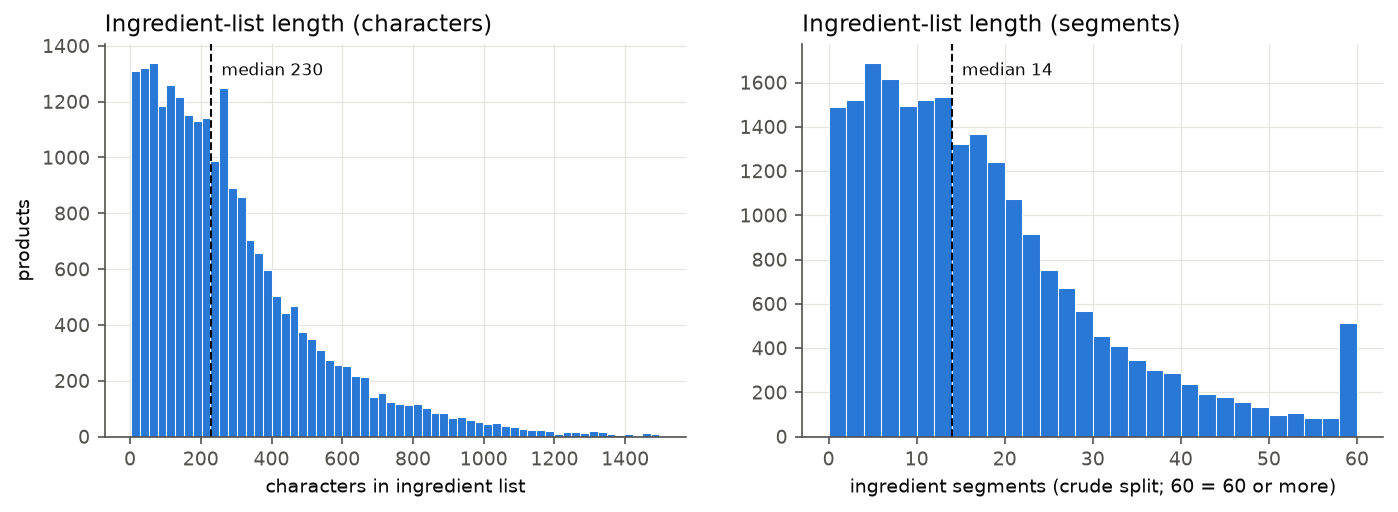

In [3]:
show("reports/figures/02_ingredient_length_distribution.png", 620)

## 2. Preprocessing: normalisation, tokenisation, regular expressions, sub-words

* **Normalisation**: unify Unicode, spacing and punctuation so the same text always looks the same.
* **Tokenisation with character offsets**: every token remembers where it is in the text, so labels can
  be mapped back to the exact characters (needed for highlighting and for BIO tags).
* **Regular expressions**: additive codes are written many ways (`INS 330`, `E-330`, `(330)`, `503(ii)`);
  one set of patterns maps them all to a canonical number.
* **Sub-word tokenisation (WordPiece)**: DistilBERT splits rare or misspelled words into known pieces,
  so it can still process words it has never seen.

In [4]:
from src.preprocessing.pipeline import process_ingredient_text
from src.preprocessing.additive_codes import normalize_code

p = process_ingredient_text("INGREDIENTS:  Sugar,  Palm Oil , Acidity Regulator (INS 330), Emulsifier E-471, "
                            "Raising agent 503(ii), Hazelnuts (13%)")
print("normalised text:", p["text"])
display(pd.DataFrame({"token": p["tokens"], "start": [s for s, _ in p["token_offsets"]],
                      "end": [e for _, e in p["token_offsets"]]}).head(14).T)
print("additive codes found:", [(c["text"], c["number"]) for c in p["additive_codes"]])
print("percentages found:   ", [(x["text"], x["value"]) for x in p["percentages"]])

normalised text: INGREDIENTS: Sugar, Palm Oil , Acidity Regulator (INS 330), Emulsifier E-471, Raising agent 503(ii), Hazelnuts (13%)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
token,INGREDIENTS,:,Sugar,",",Palm,Oil,",",Acidity,Regulator,(,INS,330,),","
start,0,11,13,18,20,25,29,31,39,49,50,54,57,58
end,11,12,18,19,24,28,30,38,48,50,53,57,58,59


additive codes found: [('INS 330', '330'), ('E-471', '471'), ('503(ii)', '503ii')]
percentages found:    [('13%', 13.0)]


In [5]:
for code_text in ["INS 330", "E-330", "E330", "330", "503(ii)", "INS 503 (ii)", "E150d", "Hazelnuts"]:
    print(f"{code_text:14} -> {normalize_code(code_text)}")

INS 330        -> 330
E-330          -> 330
E330           -> 330
330            -> 330
503(ii)        -> 503ii
INS 503 (ii)   -> 503ii
E150d          -> 150d
Hazelnuts      -> None


In [6]:
from transformers import AutoTokenizer
wordpiece = AutoTokenizer.from_pretrained("models/ingredient-ner-distilbert")
for word in ["sugar", "sucralose", "maltodextrin", "dextr0se", "carrageenan"]:
    print(f"{word:14} -> {wordpiece.tokenize(word)}")

sugar          -> ['sugar']
sucralose      -> ['su', '##cr', '##alo', '##se']
maltodextrin   -> ['mal', '##to', '##de', '##xt', '##rin']
dextr0se       -> ['dex', '##tr', '##0s', '##e']
carrageenan    -> ['carr', '##age', '##ena', '##n']


## 3. Weak supervision and BIO tagging

No labelled dataset existed, so the training labels were made **automatically** (*weak supervision*):
curated dictionaries (sugars, fats, sweeteners, flavourings, additive names and codes) plus rules
(e.g. a segment whose last word is *oil* is a FAT). These are **silver** labels: not checked by humans.

Entities are encoded with **BIO tags** (a form of chunking): `B-` = first word of an entity, `I-` = inside,
`O` = outside. 10 entity classes -> 21 tags.

In [7]:
from src.labeling.weak_labeler import label_text
from src.labeling.bio import entities_to_bio

lab = label_text("Sugar, glucose syrup, refined palm oil, acidity regulator (INS 330), natural flavourings")
display(pd.DataFrame(lab["entities"])[["text", "label", "rule"]])
bio = entities_to_bio(lab["token_offsets"], lab["entities"])
display(pd.DataFrame({"token": lab["tokens"], "BIO tag": bio}).T)

,text,label,rule
0,Sugar,SUGAR,dict:sugars
1,glucose syrup,SUGAR,dict:sugars
2,refined palm oil,FAT,head:fat_word
3,acidity regulator,FUNCTION_CLASS,dict:function_classes
4,INS 330,INS_CODE,regex:ins_code_INS
5,natural flavourings,FLAVOURING,head:flavour_word


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
token,Sugar,",",glucose,syrup,",",refined,palm,oil,",",acidity,regulator,(,INS,330,),",",natural,flavourings
BIO tag,B-SUGAR,O,B-SUGAR,I-SUGAR,O,B-FAT,I-FAT,I-FAT,O,B-FUNCTION_CLASS,I-FUNCTION_CLASS,O,B-INS_CODE,I-INS_CODE,O,O,B-FLAVOURING,I-FLAVOURING


silver corpus split (products with the same name/brand are kept in one split): {'train': 15556, 'validation': 3280, 'test': 3487}


training entities: 248,970


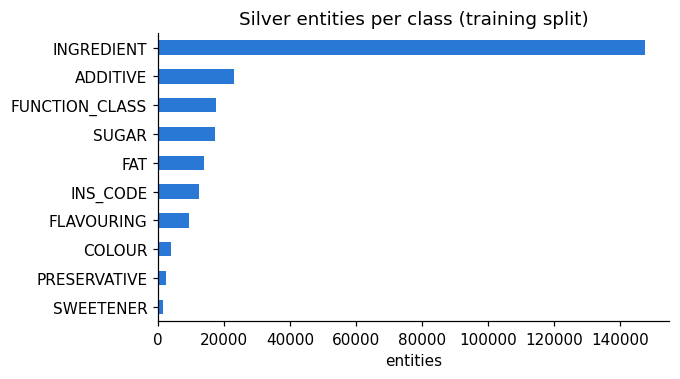

In [8]:
from src.ner.data import load_split, noisy_copy, tags_of
split_sizes = {s: len(load_split("silver", s)) for s in ("train", "validation", "test")}
print("silver corpus split (products with the same name/brand are kept in one split):", split_sizes)
train = load_split("silver", "train")
counts = Counter(e["label"] for r in train for e in r["entities"])
print(f"training entities: {sum(counts.values()):,}")
ax = pd.Series(counts).sort_values().plot.barh(figsize=(6, 3.4), color="#2a78d6")
ax.set_title("Silver entities per class (training split)"); ax.set_xlabel("entities"); plt.show()

## 4. Named entity recognition: rules vs CRF vs DistilBERT

The core NLP task: label every ingredient with one of 10 classes. Three families of tagger:

| System | Type | Idea |
|---|---|---|
| Dictionary rules | rule-based | exact dictionary and head-word matches (these also made the silver labels) |
| CRF | statistical sequence model | word-shape, affix and context features; learns tag transitions |
| DistilBERT | transformer (deep learning) | pretrained language model fine-tuned on the silver labels, with OCR-noise augmentation |

Below, all three tag the same OCR-damaged list. The rules miss words with OCR slips (`dextr0se`, `oii`);
the noise-trained DistilBERT recovers most of them.

In [9]:
from src.baseline.dictionary_ner import DictionaryNER
from src.ner.crf_baseline import CRFTagger
from src.ner.transformer_ner import TransformerTagger

dictionary_ner = DictionaryNER()
crf = CRFTagger()
distilbert = TransformerTagger("models/ingredient-ner-distilbert")

def dictionary_tags(records):
    return [entities_to_bio(r["token_offsets"], dictionary_ner.predict_record(r)) for r in records]

ocr_like = "sugar, dextr0se, palm oii, acidity regulator (INS 33O), maltodexirin, colour (caramel E150d)"
p = process_ingredient_text(ocr_like)
display(pd.DataFrame({"token": p["tokens"], "rules": dictionary_tags([p])[0],
                      "CRF": crf.predict_tags(p["tokens"]), "DistilBERT": distilbert.predict_tags(p["tokens"])}).T)

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
token,sugar,",",dextr0se,",",palm,oii,",",acidity,regulator,(,...,33O,),",",maltodexirin,",",colour,(,caramel,E150d,)
rules,B-SUGAR,O,O,O,B-INGREDIENT,I-INGREDIENT,O,B-FUNCTION_CLASS,I-FUNCTION_CLASS,O,...,I-INGREDIENT,O,O,O,O,B-FUNCTION_CLASS,O,B-INGREDIENT,B-INS_CODE,O
CRF,B-SUGAR,O,O,O,B-INGREDIENT,I-INGREDIENT,O,B-FUNCTION_CLASS,I-FUNCTION_CLASS,O,...,I-INS_CODE,O,O,O,O,B-FUNCTION_CLASS,O,B-INGREDIENT,B-INS_CODE,O
DistilBERT,B-SUGAR,O,B-SUGAR,O,B-FAT,I-FAT,O,B-FUNCTION_CLASS,I-FUNCTION_CLASS,O,...,I-INS_CODE,O,O,B-INGREDIENT,O,B-FUNCTION_CLASS,O,B-INGREDIENT,B-INS_CODE,O


## 5. Evaluation: precision, recall, F1, robustness to OCR noise, error analysis

**Strict entity-level micro F1**: an entity counts as correct only if its span *and* class match exactly.
Because photos produce OCR errors, every system is also tested on the same test lists with synthetic
OCR-style character confusions (`l`<->`1`, `O`<->`0`, ...) at 5% and 10% of characters.

**Live check** on 300 held-out test products (runs in under a minute):

test set,clean,5% OCR noise,10% OCR noise
system,,,
CRF,0.950,0.866,0.792
DistilBERT + noise aug.,0.948,0.925,0.907
dictionary rules,1.000,0.861,0.741


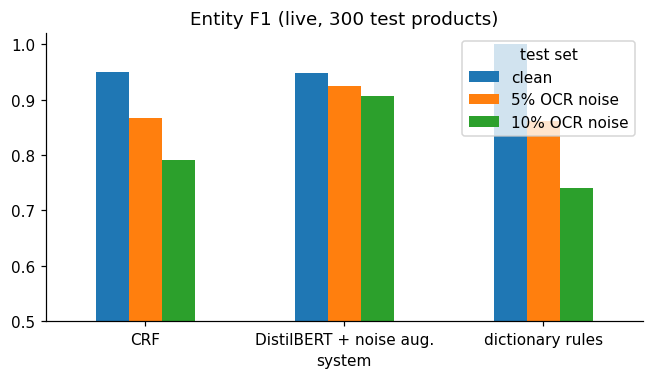

In [10]:
from src.evaluation.metrics import evaluate_tag_sequences

test = load_split("silver", "test", limit=300, seed=7)
eval_sets = {"clean": test, "5% OCR noise": noisy_copy(test, 0.05, seed=1), "10% OCR noise": noisy_copy(test, 0.10, seed=2)}
systems = {"dictionary rules": dictionary_tags, "CRF": crf.predict_records, "DistilBERT + noise aug.": distilbert.predict_records}
rows = []
for name, predict in systems.items():
    for set_name, records in eval_sets.items():
        micro = evaluate_tag_sequences([tags_of(r) for r in records], predict(records))["micro"]
        rows.append({"system": name, "test set": set_name, "precision": micro["precision"],
                     "recall": micro["recall"], "F1": micro["f1"]})
live = pd.DataFrame(rows)
display(live.pivot(index="system", columns="test set", values="F1")[["clean", "5% OCR noise", "10% OCR noise"]].round(3))
live.pivot(index="system", columns="test set", values="F1")[["clean", "5% OCR noise", "10% OCR noise"]].plot.bar(
    figsize=(7, 3.4), rot=0, ylim=(0.5, 1.02), title="Entity F1 (live, 300 test products)"); plt.show()

On clean text the rules score 1.0 **by construction** (they made the reference labels). The honest
comparison is on noisy text, where the noise-trained transformer is clearly the most robust.

**Full saved results** (1,000 test products, all six systems, from `python -m src.ner.evaluate_models`):

,silver_test,noisy_test_0.05,noisy_test_0.10,sentences_per_second
dictionary,1.000,0.862,0.734,1113.9
crf,0.949,0.872,0.796,664.0
bert,0.929,0.852,0.767,14.4
distilbert,0.943,0.834,0.719,46.9
distilbert_aug,0.940,0.922,0.900,44.5
distilbert_crf,0.950,0.851,0.747,48.3


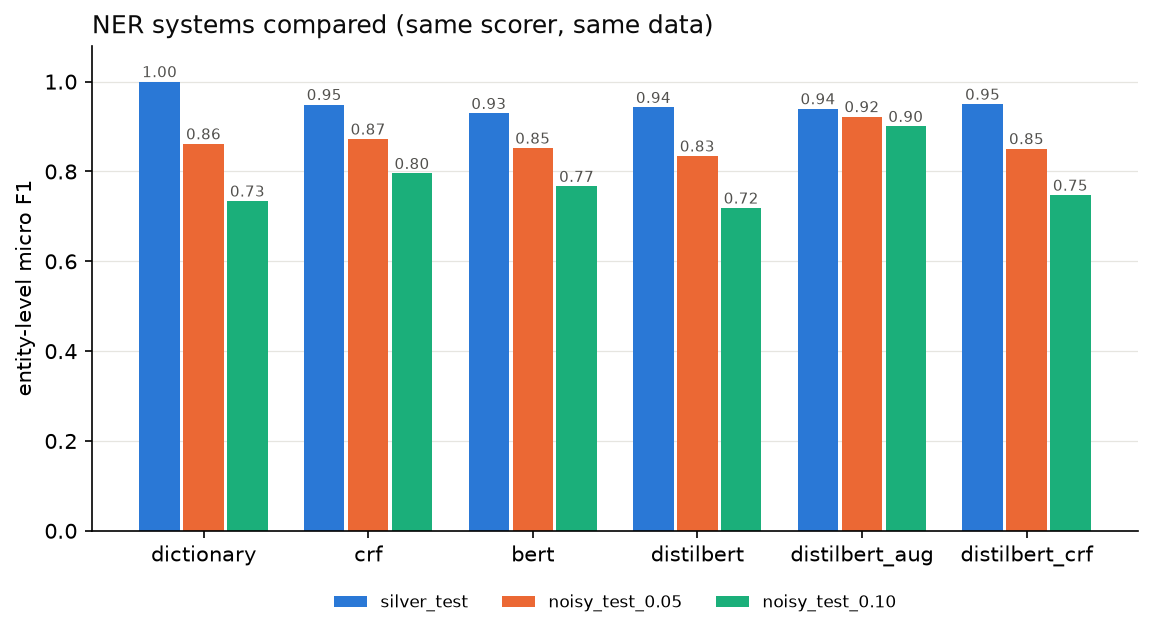

In [11]:
summary = pd.DataFrame(load("reports/model_comparison.json")["summary_f1"]).T
display(summary.round(3))
show("reports/figures/12_model_comparison.png")

,precision,recall,f1,support
SUGAR,0.960,0.969,0.964,1150.0
SWEETENER,0.880,0.820,0.849,89.0
FAT,0.922,0.959,0.940,950.0
PRESERVATIVE,0.861,0.890,0.875,146.0
COLOUR,0.808,0.863,0.834,219.0
ADDITIVE,0.849,0.938,0.891,1444.0
INS_CODE,0.832,0.971,0.896,697.0
FUNCTION_CLASS,0.888,0.949,0.917,1091.0
FLAVOURING,0.887,0.917,0.902,581.0
INGREDIENT,0.914,0.941,0.927,9760.0


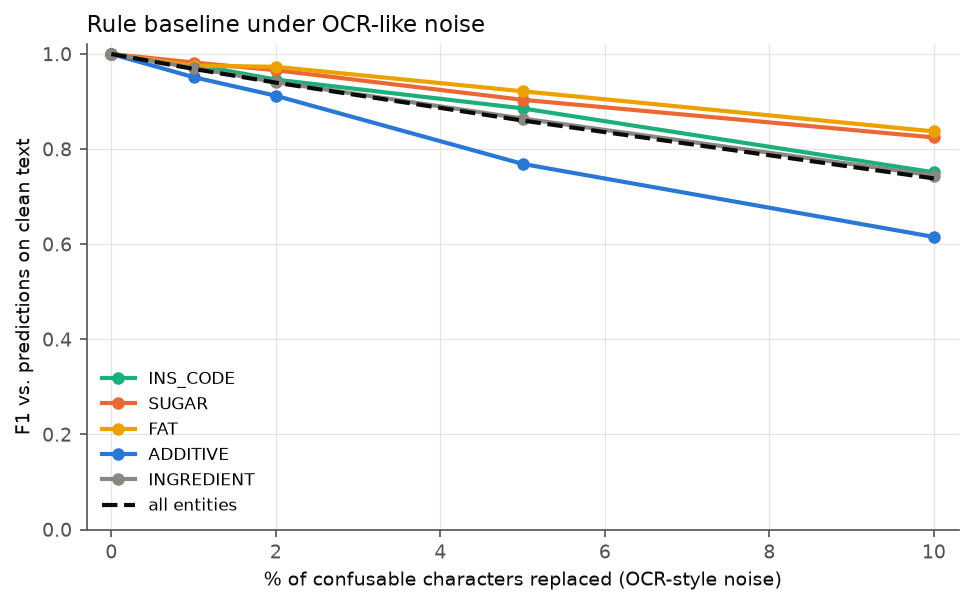

In [12]:
details = load("reports/model_comparison.json")["details"]["distilbert_aug"]["noisy_test_0.05"]["per_class"]
display(pd.DataFrame(details).T[["precision", "recall", "f1", "support"]].round(3))
show("reports/figures/11_noise_robustness.png", 560)

**Error analysis** of the augmented DistilBERT on the 5% noise set: which kinds of mistakes does it make?

In [13]:
errors = pd.read_csv("reports/error_analysis/distilbert_aug_errors_noisy_test_0.05.csv")
display(errors["error_type"].value_counts().rename("errors").to_frame())
errors[["expected_entity", "expected_label", "predicted_entity", "predicted_label", "error_type"]].dropna(subset=["expected_entity"]).sample(6, random_state=3)

,errors
error_type,
false_positive,824
boundary_error,322
false_negative,251
type_error,213
boundary_and_type,137


,expected_entity,expected_label,predicted_entity,predicted_label,error_type
1427,26% VEGETA8LE FAT,FAT,VEGETA8LE FAT,FAT,boundary_error
919,Lysazyme,PRESERVATIVE,Lysazyme,ADDITIVE,type_error
1152,1422,INS_CODE,NaN,NaN,false_negative
1535,milk flavour qums and sweet foam gums/ihgredients,FLAVOURING,milk flavour qums and sweet foam gums/ihgredients glucosc,FLAVOURING,boundary_error
193,Sunflawer Lecithin,ADDITIVE,Sunflawer,INGREDIENT,boundary_and_type
724,Amina Acids,INGREDIENT,Amina Acids,ADDITIVE,type_error


## 6. Spelling correction and edit distance

OCR slips are repaired with **SymSpell** and a 6,400-word food dictionary built from the 22,000 real lists.
**Levenshtein (edit) distance** = the number of single-character insertions, deletions and substitutions
between two strings; it drives correction, fuzzy matching and the OCR error rates below.

In [14]:
from src.ocr.text_correction import correct_ocr_text
from rapidfuzz.distance import Levenshtein

raw = "flavcurenhancers, maltodexrin, slarch, dextr0se, Emu1sifier (INS 322), regu1ator (330)"
print("OCR text :", raw)
print("corrected:", correct_ocr_text(raw))
for a, b in [("maltodexirin", "maltodextrin"), ("dextr0se", "dextrose"), ("sugar", "salt")]:
    print(f"edit distance {a!r} -> {b!r}: {Levenshtein.distance(a, b)}  (similarity {Levenshtein.normalized_similarity(a, b):.2f})")

OCR text : flavcurenhancers, maltodexrin, slarch, dextr0se, Emu1sifier (INS 322), regu1ator (330)
corrected: flavour enhancers, maltodextrin, starch, dextrose, Emulsifier (INS 322), regulator (330)
edit distance 'maltodexirin' -> 'maltodextrin': 1  (similarity 0.92)
edit distance 'dextr0se' -> 'dextrose': 1  (similarity 0.88)
edit distance 'sugar' -> 'salt': 4  (similarity 0.20)


## 7. OCR quality: character and word error rate (CER, WER)

For the 60 real packet photos we know the product's typed ingredient list (the reference). We compare it
with the ingredient section the app extracted from the photo:

* **CER** = character edit distance / reference length
* **WER** = **word** edit distance (substituted + deleted + inserted words) / number of reference words

Version 1 of the app used EasyOCR; version 2 uses RapidOCR (PP-OCRv6) with enlargement, rotation and
spelling correction. (WER can exceed 1 when the extracted section contains extra text.)

,photos,median CER,median WER,photos with WER < 0.3
v1: EasyOCR,60,0.622,0.890,15
v2: RapidOCR + correction,60,0.220,0.302,30


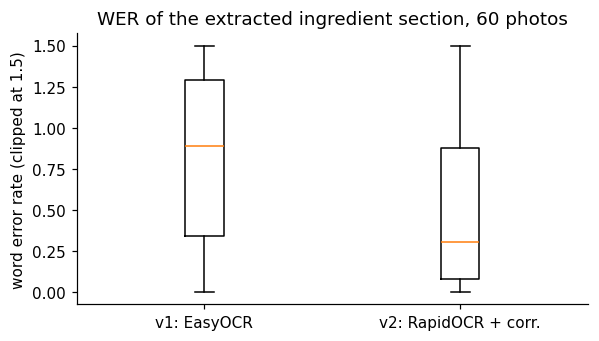

In [15]:
from src.ocr.section_extraction import extract_ingredients_section

reference = {r["id"]: r["text"] for r in load_split("silver", "test")}
words = lambda t: re.findall(r"[a-z0-9]+", t.lower())

def error_rates(cache_path):
    rows = []
    for line in (ROOT / cache_path).read_text(encoding="utf-8").splitlines():
        r = json.loads(line)
        if r["product_id"] not in reference:
            continue
        section = extract_ingredients_section(r["corrected_text"])["text"]
        ref = reference[r["product_id"]]
        rows.append({"product": r["product_id"],
                     "CER": Levenshtein.normalized_distance(" ".join(words(ref)), " ".join(words(section))),
                     "WER": Levenshtein.distance(words(ref), words(section)) / max(1, len(words(ref)))})
    return pd.DataFrame(rows)

v1 = error_rates("reports/ocr_easyocr_v1/ocr_results.jsonl")
v2 = error_rates("data/images/ocr_results.jsonl")
table = pd.DataFrame({"photos": [len(v1), len(v2)], "median CER": [v1.CER.median(), v2.CER.median()],
                      "median WER": [v1.WER.median(), v2.WER.median()],
                      "photos with WER < 0.3": [(v1.WER < 0.3).sum(), (v2.WER < 0.3).sum()]},
                     index=["v1: EasyOCR", "v2: RapidOCR + correction"])
display(table.round(3))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.boxplot([v1.WER.clip(upper=1.5), v2.WER.clip(upper=1.5)], labels=["v1: EasyOCR", "v2: RapidOCR + corr."])
ax.set_ylabel("word error rate (clipped at 1.5)"); ax.set_title("WER of the extracted ingredient section, 60 photos"); plt.show()

**One live scan** of a real photo (OCR -> clean-up -> section -> hybrid NER -> knowledge base):

In [16]:
from src.app.scanner import IngredientScanner
scanner = IngredientScanner()
result = scanner.scan_image("data/images/unseen/8000500225615.jpg")
print({k: result["ocr"][k] for k in ("engine", "rotation", "scale", "n_lines", "mean_confidence", "section_method", "seconds")})
print("\ningredient section read:\n", result["text"][:300])
display(pd.DataFrame(result["entities"])[["text", "label", "source", "canonical_name", "ins_number"]].head(12))

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

{'engine': 'RapidOCR (PP-OCRv6)', 'rotation': 0, 'scale': 1.09, 'n_lines': 38, 'mean_confidence': 0.91, 'section_method': 'keyword', 'seconds': 4.4}

ingredient section read:
 SUGAR, EDIBLE VEGETABLE OIL, HAZELNUTS (13%), LOW FAT COCOA POWDER(7.4%), SKIMMED COW MILK POWDER (6.6%), WHEY POWDER, EMULSIFIER (LECITHIN -INS 322). CONTAINS ADDED FLAVOUR (NATURE- IDENTICAL FLAVOURING SUBSTANCE-VANILLIN)


,text,label,source,canonical_name,ins_number
0,SUGAR,SUGAR,dictionary,sugar,
1,EDIBLE VEGETABLE OIL,FAT,dictionary,,
2,HAZELNUTS,INGREDIENT,dictionary,,
3,LOW FAT COCOA POWDER,INGREDIENT,dictionary,,
4,SKIMMED COW MILK POWDER,INGREDIENT,dictionary,,
5,WHEY POWDER,INGREDIENT,dictionary,,
6,EMULSIFIER,FUNCTION_CLASS,dictionary,Emulsifier,
7,LECITHIN,ADDITIVE,dictionary,Lecithins,322
8,INS 322,INS_CODE,dictionary,Lecithins,322
9,ADDED FLAVOUR,FLAVOURING,dictionary,,


## 8. N-gram language model, smoothing and perplexity

A **bigram model** estimates P(word | previous word) from counts in the training lists; a **trigram**
model uses the two previous words. Unseen word pairs would get probability 0, so the counts are
**smoothed**: add-k (Laplace when k = 1) or **interpolation** (mix trigram, bigram and unigram estimates).

**Perplexity** = 2^(average negative log2 probability per word): how "surprised" the model is by new text.
Lower = more predictable. We compare the models on held-out test lists, then show how much OCR errors
make text less predictable.

In [17]:
import math

def lm_words(text):
    return ["<s>", "<s>"] + re.findall(r"[a-z]+|\d+|[,;:()\[\]]", text.lower()) + ["</s>"]

train_texts = [r["text"] for r in train]
validation_texts = [r["text"] for r in load_split("silver", "validation", limit=1000, seed=1)]
test_texts = [r["text"] for r in load_split("silver", "test", limit=1000, seed=1)]

unigram_counts = Counter(w for t in train_texts for w in lm_words(t)[2:])
VOCAB = {w for w, c in unigram_counts.items() if c >= 2} | {"<unk>", "</s>"}
def tokens(text):
    return [w if w in VOCAB or w == "<s>" else "<unk>" for w in lm_words(text)]

class NGramLM:
    def __init__(self, texts):
        self.uni, self.bi, self.tri = Counter(), Counter(), Counter()
        self.ctx1, self.ctx2 = Counter(), Counter()
        for t in texts:
            w = tokens(t)
            for i in range(2, len(w)):
                self.uni[w[i]] += 1
                self.bi[(w[i-1], w[i])] += 1; self.ctx1[w[i-1]] += 1
                self.tri[(w[i-2], w[i-1], w[i])] += 1; self.ctx2[(w[i-2], w[i-1])] += 1
        self.total, self.V = sum(self.uni.values()), len(VOCAB)
    def p_unigram(self, w):            return (self.uni[w] + 1) / (self.total + self.V)
    def p_bigram(self, a, w, k):       return (self.bi[(a, w)] + k) / (self.ctx1[a] + k * self.V)
    def p_trigram(self, a, b, w, k):   return (self.tri[(a, b, w)] + k) / (self.ctx2[(a, b)] + k * self.V)
    def p_interp(self, a, b, w, l):
        p3 = self.tri[(a, b, w)] / self.ctx2[(a, b)] if self.ctx2[(a, b)] else 0
        p2 = self.bi[(b, w)] / self.ctx1[b] if self.ctx1[b] else 0
        return l[0] * p3 + l[1] * p2 + l[2] * self.p_unigram(w)

def perplexity(prob, texts):
    log_sum, n = 0.0, 0
    for t in texts:
        w = tokens(t)
        for i in range(2, len(w)):
            log_sum += -math.log2(prob(w[i-2], w[i-1], w[i])); n += 1
    return 2 ** (log_sum / n)

lm = NGramLM(train_texts)
print(f"vocabulary {lm.V:,} word types, {lm.total:,} training tokens")

vocabulary 8,401 word types, 968,859 training tokens


interpolation weights (trigram, bigram, unigram) chosen on validation: (0.6, 0.3, 0.1)


,test perplexity
unigram (add-1),193.4
"bigram, Laplace (add-1)",109.0
"bigram, add-k (k=0.01)",34.6
"trigram, add-k (k=0.01)",39.5
"trigram, interpolated",21.0


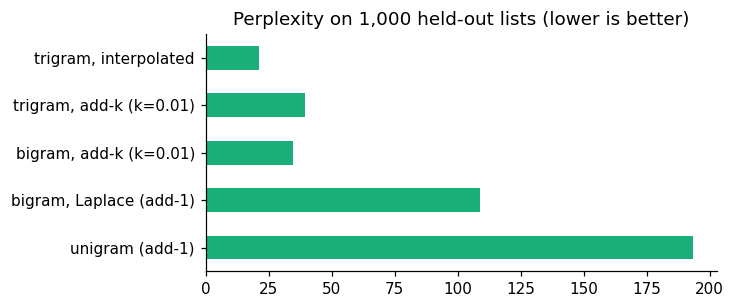

In [18]:
# interpolation weights: choose the best on the VALIDATION lists (never on the test lists)
grid = [(a, b, round(1 - a - b, 2)) for a in (0.2, 0.4, 0.6) for b in (0.2, 0.3, 0.4) if a + b < 1]
best_l = min(grid, key=lambda l: perplexity(lambda a, b, w: lm.p_interp(a, b, w, l), validation_texts))
print("interpolation weights (trigram, bigram, unigram) chosen on validation:", best_l)

models = {
    "unigram (add-1)":            lambda a, b, w: lm.p_unigram(w),
    "bigram, Laplace (add-1)":    lambda a, b, w: lm.p_bigram(b, w, 1.0),
    "bigram, add-k (k=0.01)":     lambda a, b, w: lm.p_bigram(b, w, 0.01),
    "trigram, add-k (k=0.01)":    lambda a, b, w: lm.p_trigram(a, b, w, 0.01),
    "trigram, interpolated":      lambda a, b, w: lm.p_interp(a, b, w, best_l),
}
ppl = pd.Series({name: perplexity(prob, test_texts) for name, prob in models.items()}, name="test perplexity")
display(ppl.round(1).to_frame())
ppl.plot.barh(figsize=(6, 2.8), color="#1baf7a", title="Perplexity on 1,000 held-out lists (lower is better)"); plt.show()

Laplace smoothing gives too much probability to unseen pairs, so the bigram model with add-1 does
*worse* than with a small k; interpolation does best. **Next-word prediction** with the best model:

In [19]:
best = models["trigram, interpolated"]
for context in [("glucose",), ("palm",), ("acidity",), ("skimmed", "milk")]:
    a, b = (["<s>"] + list(context))[-2:]
    ranked = sorted(VOCAB - {"<unk>"}, key=lambda w: -best(a, b, w))[:5]
    print(f"after {' '.join(context)!r:22} -> {ranked}")

after 'glucose'              -> ['syrup', 'fructose', ',', '(', ')']
after 'palm'                 -> ['oil', 'kernel', 'fat', 'sugar', ',']
after 'acidity'              -> ['regulators', 'regulator', ',', ')', '(']
after 'skimmed milk'         -> ['powder', ',', ')', '(', 'solids']


**How much do OCR errors disrupt the text?** Perplexity of the same test lists, clean vs with OCR noise, and of the sections read from real photos:

In [20]:
noisy5 = [r["text"] for r in noisy_copy(load_split("silver", "test", limit=1000, seed=1), 0.05, seed=1)]
noisy10 = [r["text"] for r in noisy_copy(load_split("silver", "test", limit=1000, seed=1), 0.10, seed=2)]
photos = [extract_ingredients_section(json.loads(l)["corrected_text"])["text"]
          for l in (ROOT / "data/images/ocr_results.jsonl").read_text(encoding="utf-8").splitlines()]
photo_refs = [reference[json.loads(l)["product_id"]] for l in (ROOT / "data/images/ocr_results.jsonl").read_text(encoding="utf-8").splitlines()]
display(pd.Series({"test lists, clean": perplexity(best, test_texts), "same lists, 5% OCR noise": perplexity(best, noisy5),
                   "same lists, 10% OCR noise": perplexity(best, noisy10),
                   "60 photos: typed reference": perplexity(best, photo_refs),
                   "60 photos: section read by the app": perplexity(best, photos)},
                  name="perplexity").round(1).to_frame())

,perplexity
"test lists, clean",21.0
"same lists, 5% OCR noise",37.2
"same lists, 10% OCR noise",55.7
60 photos: typed reference,24.7
60 photos: section read by the app,66.9


## 9. Entity linking, synonymy and fuzzy matching

Each recognised entity is **linked** to the knowledge base (731 additives from the Open Food Facts
taxonomy, function classes, ingredient terms). Methods, tried in order: INS/E number -> exact name or
**synonym** (E330 = INS 330 = citric acid) -> official additive name -> **fuzzy** name (Levenshtein
similarity >= 88, for OCR slips) -> category description only.

In [21]:
from src.kb.entity_linking import get_linker
linker = get_linker()
examples = [{"text": "INS 330", "label": "INS_CODE"}, {"text": "E150d", "label": "INS_CODE"},
            {"text": "soy lecithin", "label": "ADDITIVE"}, {"text": "lecithln", "label": "ADDITIVE"},
            {"text": "sodium benzoate", "label": "PRESERVATIVE"}, {"text": "Yellow 5", "label": "COLOUR"}]
pd.DataFrame([{"entity": e["text"], **{k: v for k, v in linker.link(e).items()
               if k in ("canonical_name", "ins_number", "function", "link_method", "link_score")}} for e in examples])

,entity,canonical_name,ins_number,function,link_method,link_score
0,INS 330,Citric acid,330,"Antioxidant, Sequestrant",ins_number,1.0
1,E150d,Sulphite ammonia caramel,150d,Colour,ins_number,1.0
2,soy lecithin,Lecithins,322,"Antioxidant, Emulsifier",exact_name,1.0
3,lecithln,,,,category,0.0
4,sodium benzoate,Sodium benzoate,211,Preservative,exact_name,1.0
5,Yellow 5,Tartrazine,102,Colour,exact_name,1.0


## 10. Text representations and similarity measures

When a photo shows no nutrition table, the app estimates nutrition from the **most similar product** in
the database. Which representation finds the best match?

* **Bag of Words (BoW)**: a list = its word counts
* **TF-IDF**: counts weighted by rarity (common words like *salt* count less)
* **Jaccard**: shared words / all words; **cosine**: angle between vectors;
  **Euclidean** and **Manhattan**: distances between vectors

A small example first:

In [22]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances, manhattan_distances

docs = {"chocolate spread": "sugar, palm oil, hazelnuts, cocoa, skimmed milk powder, lecithin, vanillin",
        "hazelnut cream":   "sugar, hazelnuts, vegetable oil, cocoa powder, milk powder, emulsifier lecithin",
        "potato chips":     "potato, palm oil, salt, maltodextrin, flavour enhancer, citric acid"}
bow = CountVectorizer().fit_transform(docs.values())
tfidf = TfidfVectorizer().fit_transform(docs.values())
sets = [set(re.findall(r"[a-z]+", d)) for d in docs.values()]
names = list(docs)
print("Jaccard:"); display(pd.DataFrame([[len(a & b) / len(a | b) for b in sets] for a in sets], names, names).round(2))
print("Cosine on TF-IDF:"); display(pd.DataFrame(cosine_similarity(tfidf), names, names).round(2))
print("Euclidean on BoW (distance, lower = closer):"); display(pd.DataFrame(euclidean_distances(bow), names, names).round(2))
print("Manhattan on BoW (distance, lower = closer):"); display(pd.DataFrame(manhattan_distances(bow), names, names).round(0))

Jaccard:


,chocolate spread,hazelnut cream,potato chips
chocolate spread,1.00,0.58,0.12
hazelnut cream,0.58,1.00,0.06
potato chips,0.12,0.06,1.00


Cosine on TF-IDF:


,chocolate spread,hazelnut cream,potato chips
chocolate spread,1.00,0.63,0.13
hazelnut cream,0.63,1.00,0.05
potato chips,0.13,0.05,1.00


Euclidean on BoW (distance, lower = closer):


,chocolate spread,hazelnut cream,potato chips
chocolate spread,0.00,2.45,3.87
hazelnut cream,2.45,0.00,4.36
potato chips,3.87,4.36,0.00


Manhattan on BoW (distance, lower = closer):


,chocolate spread,hazelnut cream,potato chips
chocolate spread,0.0,6.0,15.0
hazelnut cream,6.0,0.0,17.0
potato chips,15.0,17.0,0.0


**Evaluation** (`python -m src.evaluation.product_similarity`): for 1,320 held-out test products, the most
similar product among 6,889 database products predicts the nutrition; lower error = better representation.

,sugars MAE (g),fat MAE (g),salt MAE (g),energy MAE (kcal)
Baseline: database mean,12.88,11.07,1.28,149.87
Baseline: random product,16.55,14.72,1.80,208.98
Jaccard (word sets),6.98,6.12,1.03,79.80
BoW + Euclidean,7.99,9.73,1.26,107.57
BoW + Manhattan,7.84,10.48,1.22,111.67
BoW + cosine,7.31,6.19,1.11,82.86
TF-IDF words + cosine,7.31,6.59,1.33,87.70
TF-IDF words+pairs + cosine (app),7.63,7.30,1.36,91.52
ingredient2vec mean + cosine,8.02,6.51,1.15,89.79
TF-IDF + ingredient2vec + cosine,6.99,6.23,1.04,79.66


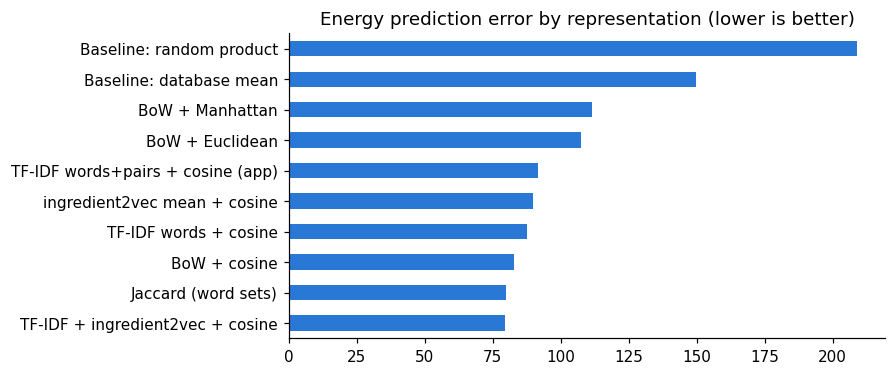

In [23]:
sim = load("reports/product_similarity.json")
table = pd.DataFrame({name: {"sugars MAE (g)": r["top1"]["sugars_g"]["mae"], "fat MAE (g)": r["top1"]["fat_g"]["mae"],
                             "salt MAE (g)": r["top1"]["salt_g"]["mae"], "energy MAE (kcal)": r["top1"]["energy_kcal"]["mae"]}
                      for name, r in sim.items()}).T
display(table)
table["energy MAE (kcal)"].sort_values().plot.barh(figsize=(7, 3.6), color="#2a78d6",
    title="Energy prediction error by representation (lower is better)"); plt.show()

## 11. Word embeddings: ingredient2vec (word2vec)

**Distributional semantics**: words that occur in similar contexts have similar meanings. We trained
**word2vec (CBOW)** on the 14,000 training lists, with each ingredient as one token (`glucose_syrup`),
so ingredients used in the same way end up close together, even with no letters in common.

In [24]:
from src.embeddings.ingredient2vec import load_model, most_similar
w2v = load_model()
print(f"{len(w2v.wv):,} ingredient vectors of {w2v.vector_size} dimensions")
for term in ["sucralose", "citric_acid", "palm_oil", "dextrose", "soya_lecithin"]:
    print(f"{term:15} -> {[t for t, _ in most_similar(term, 5, w2v)]}")

3,544 ingredient vectors of 100 dimensions
sucralose       -> ['aspartame', 'sodium_saccharin', 'sodium_cyclamate', 'sodium_gluconate', 'non-nutritive']
citric_acid     -> ['sodium_lactate', 'sodium_diacetate', 'lactic_acid', 'phosphoric_acid', 'acetic_acid']
palm_oil        -> ['palm_kernel_oil', 'coconut_oil', 'palm', 'sugar', 'refined_palm_oil']
dextrose        -> ['sugar', 'wheat_starch', 'modified_potato_starch', 'salt', 'sodium_diacetate']
soya_lecithin   -> ['soya_lecithins', 'sunflower_lecithins', 'sunflower_lecithin', 'lecithins', 'mono-and_di-glycerides_of_fatty_acids']


**Evaluation: do the vectors know an ingredient's category?** 866 terms whose category the rules know,
classified by k-nearest neighbours (5-fold cross-validation). The vectors never saw the labels.

,accuracy,macro F1
majority class,0.288,NaN
spelling (char 3-grams),0.905,0.858
ingredient2vec (context),0.739,0.734
spelling + context,0.934,0.930


Configurations compared (window x architecture):


,window,architecture,w2v_accuracy,w2v_macro_f1,combined_accuracy,combined_macro_f1
0,2,CBOW,0.741,0.729,0.931,0.923
1,2,skip-gram,0.663,0.609,0.930,0.906
2,3,CBOW,0.739,0.734,0.934,0.930
3,3,skip-gram,0.659,0.612,0.927,0.910
4,5,CBOW,0.710,0.693,0.928,0.917
5,5,skip-gram,0.633,0.585,0.925,0.907


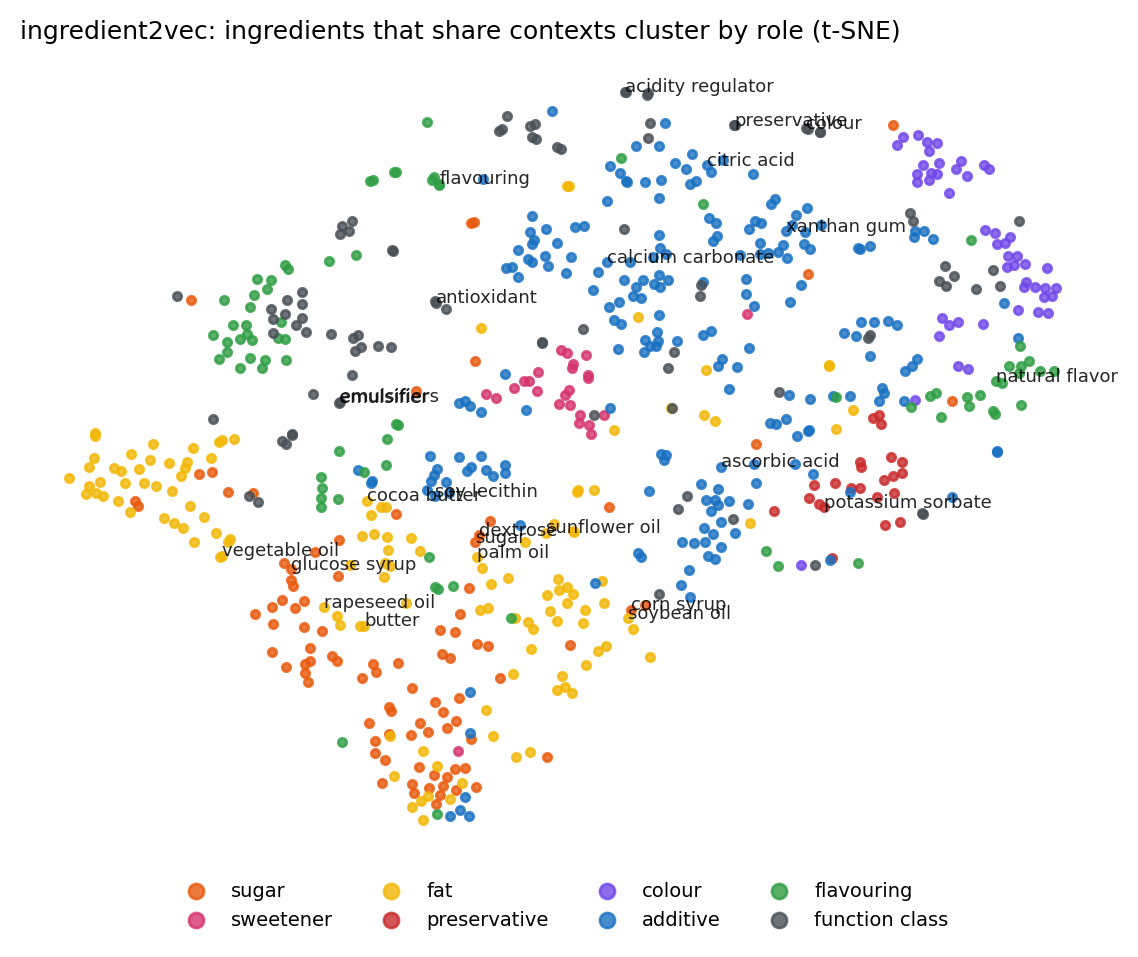

In [25]:
emb = load("reports/embeddings/ingredient2vec.json")
c = emb["classification"]
display(pd.DataFrame({"accuracy": [c["majority_class"]["accuracy"], c["spelling_char3gram_knn"]["accuracy"],
                                   c["ingredient2vec_knn"]["accuracy"], c["spelling_plus_ingredient2vec_knn"]["accuracy"]],
                      "macro F1": [None, c["spelling_char3gram_knn"]["macro_f1"], c["ingredient2vec_knn"]["macro_f1"],
                                   c["spelling_plus_ingredient2vec_knn"]["macro_f1"]]},
                     index=["majority class", "spelling (char 3-grams)", "ingredient2vec (context)", "spelling + context"]))
print("Configurations compared (window x architecture):")
display(pd.DataFrame(emb["grid"]))
show("reports/figures/14_ingredient2vec_tsne.png", 640)

### 11b. Using the embeddings: sub-groups for "Other ingredients"

The NER schema has one generic INGREDIENT class. Those ingredients are sorted afterwards into sub-groups
(protein, fibre, probiotics, enzymes, grains, dairy, spices ...): first by ordered **name rules**, and for
names no rule covers by **k-nearest neighbours in the ingredient2vec space** (similarity-weighted vote of
the closest rule-labelled ingredients; only used when the neighbours agree).

In [26]:
from src.kb.ingredient_subgroups import INFO, subgroup_of
for name in ["Chicory Root Fiber", "Probiotic Bacillus Coagulans", "Bromelain & Papain", "Whey protein concentrate",
             "Hydrolysed Groundnut Protein", "Gram Meal", "kasuri methi", "Sultanas"]:
    group, method = subgroup_of(name)
    print(f"{name:30} -> {INFO[group]['icon']} {INFO[group]['title']:28} ({method or 'no group'})")
sub = load("reports/ingredient_subgroups.json")
print(f"\nembedding fallback, tested on {sub['rule_labelled_terms']:,} held-out rule-labelled terms: answers "
      f"{sub['coverage']:.0%} of them with {sub['accuracy_when_answered']:.1%} accuracy "
      f"(majority baseline {sub['majority_baseline']['accuracy']:.1%})")
display(pd.DataFrame(sub["grid"], columns=["min similarity", "min share of votes", "answered", "accuracy"]))

Chicory Root Fiber             -> 🌱 Fibres                       (rule)
Probiotic Bacillus Coagulans   -> 🧫 Probiotics & cultures        (rule)
Bromelain & Papain             -> 🧪 Enzymes                      (rule)
Whey protein concentrate       -> 💪 Protein sources              (rule)
Hydrolysed Groundnut Protein   -> 🫙 Yeast, extracts & seasonings (rule)
Gram Meal                      -> 🫘 Legumes & soy                (rule)
kasuri methi                   -> 🌶️ Spices & herbs               (rule)
Sultanas                       -> 🍎 Fruit & vegetables           (embedding)

embedding fallback, tested on 2,177 held-out rule-labelled terms: answers 51% of them with 82.7% accuracy (majority baseline 20.8%)


,min similarity,min share of votes,answered,accuracy
0,0.45,0.5,0.676,0.756
1,0.45,0.6,0.510,0.827
2,0.45,0.7,0.390,0.874
3,0.50,0.5,0.691,0.750
4,0.50,0.6,0.548,0.803
5,0.50,0.7,0.425,0.844
6,0.55,0.5,0.680,0.735
7,0.55,0.6,0.555,0.784
8,0.55,0.7,0.454,0.810


## 12. Base paper and extension: noise-aware training (NAT)

Base paper: Namysl et al., *NAT: Noise-Aware Training for Robust Neural Sequence Labeling* (ACL 2020).
Our extension: (1) an OCR noise model **learned** from our real photos instead of hand-picked confusions,
(2) NAT's **stability training** loss: CE(clean) + alpha * KL(p_clean || p_noisy). Four DistilBERT models,
same budget (2,000 sentences, 2 epochs, seed 42).

learned from 39 photos, 8,444 letters/digits:
{'sub': '1.52%', 'del': '0.62%', 'ins': '0.14%'} per character
most common substitutions: ['l->i: 6', 'z->s: 4', 'i->l: 4', 't->e: 4', 'e->i: 3', 'd->l: 3', 'a->o: 3', 's->r: 3']


,silver_test,noisy_test_0.05,noisy_test_0.10,learned_noise_x1,learned_noise_x3
dictionary,1.000,0.862,0.734,0.888,0.707
crf,0.949,0.872,0.796,0.899,0.814
distilbert_2k,0.888,0.827,0.758,0.849,0.767
distilbert_aug_2k,0.877,0.839,0.805,0.847,0.795
distilbert_aug_learned_2k,0.881,0.841,0.802,0.854,0.804
distilbert_nat_2k,0.880,0.847,0.813,0.858,0.814


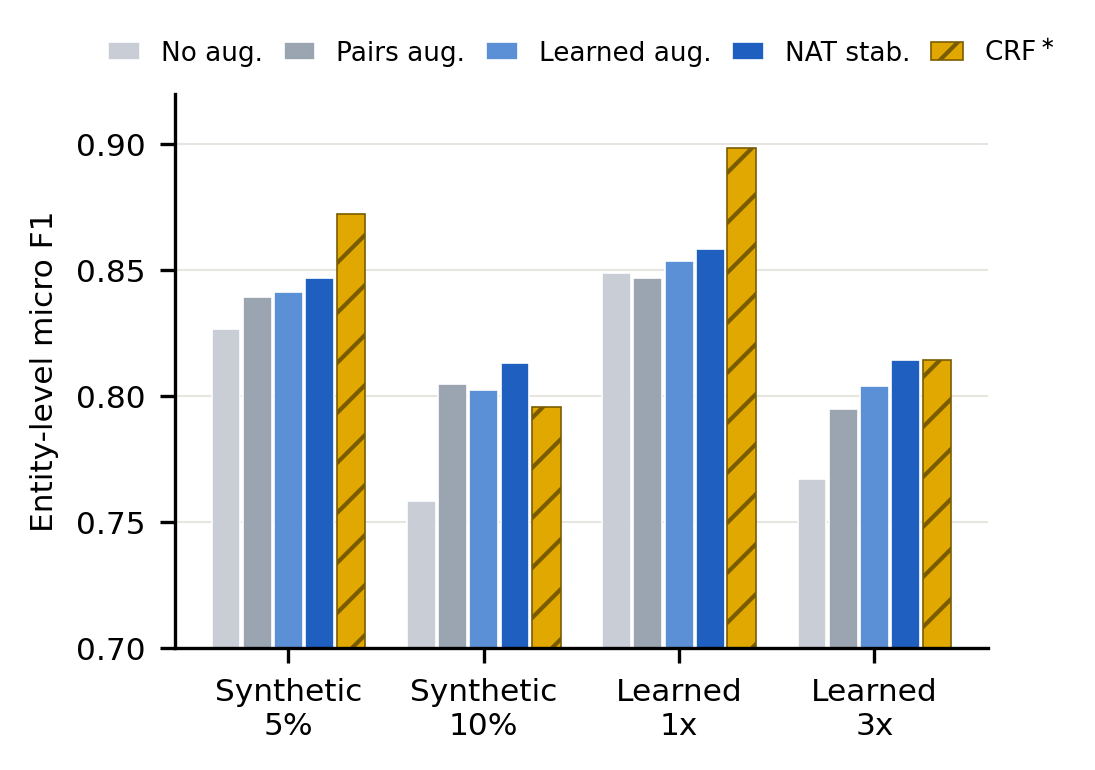

In [27]:
noise = load("data/processed/learned_ocr_noise.json")
print(f"learned from {noise['photos_used']} photos, {noise['characters']:,} letters/digits:")
print({k: f"{v:.2%}" for k, v in noise["global"].items()}, "per character")
print("most common substitutions:", noise["top_substitutions"][:8])
nat = pd.DataFrame(load("reports/nat_extension/model_comparison.json")["summary_f1"]).T
display(nat.drop(columns=["sentences_per_second"]).round(3))
show("paper/figures/fig_nat_comparison.png", 520)

## 13. The ingredient assistant: intent classification, entities, reference resolution, QA

A **retrieval-based, closed-domain question-answering system** (not a generative chatbot): every answer
comes from the knowledge base or the scan, with its source.

1. **Intent classification** (text classification): TF-IDF of words and character n-grams + logistic
   regression, compared with a keyword-rules baseline
2. **Entity extraction**: which ingredient / code is the question about (codes, names, fuzzy names)
3. **Reference resolution**: "is **it** vegan?" -> the ingredient discussed before
4. **Out-of-domain detection**: off-topic questions are declined
5. **Template-based answers** with sources; medical questions are declined

88 held-out questions: intent accuracy rules 71.6%, model 88.6%
               precision    recall  f1-score   support

    allergens       0.86      0.60      0.71        10
     contains       0.64      0.78      0.70         9
  daily_limit       0.83      1.00      0.91         5
         diet       1.00      1.00      1.00        13
list_category       1.00      0.92      0.96        13
      medical       1.00      0.90      0.95        10
      portion       1.00      1.00      1.00         2
    smalltalk       1.00      1.00      1.00         2
      what_is       1.00      0.88      0.94        17
    why_added       0.64      1.00      0.78         7

     accuracy                           0.89        88
    macro avg       0.90      0.91      0.89        88
 weighted avg       0.91      0.89      0.89        88



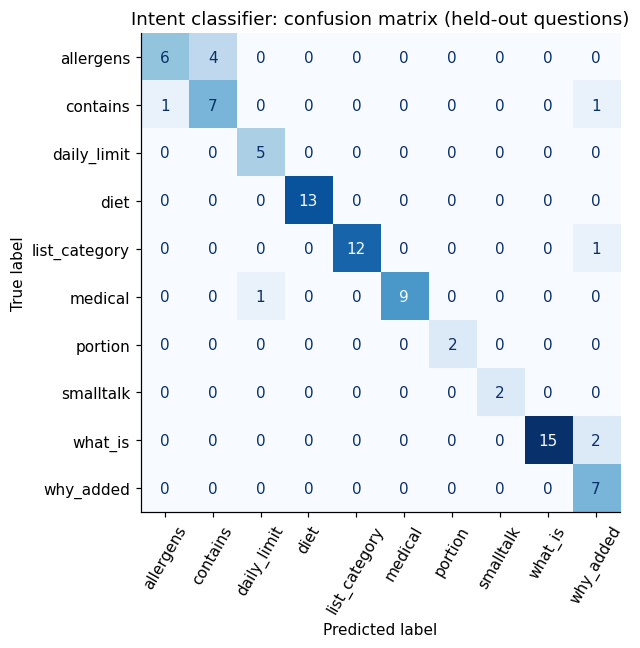

In [28]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from src.assistant.intents import model_intent, rule_intent
from src.utils.io import read_jsonl

questions = read_jsonl("data/assistant/test_questions.jsonl") + read_jsonl("data/assistant/test_questions_fresh.jsonl")
gold = [q["intent"] for q in questions]
pred_model = [model_intent(q["question"])[0] for q in questions]
pred_rules = [rule_intent(q["question"]) for q in questions]
print(f"{len(questions)} held-out questions: intent accuracy rules {np.mean(np.array(pred_rules) == gold):.1%}, "
      f"model {np.mean(np.array(pred_model) == gold):.1%}")
print(classification_report(gold, pred_model, zero_division=0))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(gold, pred_model, ax=ax, xticks_rotation=60, colorbar=False, cmap="Blues")
ax.set_title("Intent classifier: confusion matrix (held-out questions)"); plt.tight_layout(); plt.show()

**A conversation** about a scanned product (Nutella sample):

In [29]:
from src.assistant.assistant import IngredientAssistant
nutella = scanner.scan_text("Ingredients: Sugar, Palm Oil, Hazelnuts (13%), Skimmed Milk Powder (8.7%), "
                            "Fat-Reduced Cocoa (7.4%), Emulsifier: Lecithins (Soya), Vanillin.")
bot = IngredientAssistant(nutella, body_weight_kg=60)
history = []
for question in ["What is E322?", "Is it vegan?", "Which allergens does it contain?", "Is titanium dioxide banned?",
                 "My son has diabetes, can he eat this?", "What is the speed of light?"]:
    reply = bot.answer(question, history); history.append(reply)
    ref = f"  [“it” = {reply['resolved_reference']}]" if reply["resolved_reference"] else ""
    print(f"Q: {question}   -> intent: {reply['intent']}{ref}")
    print("A:", re.sub(r"\*\*", "", reply["text"])[:260], "\n")

Q: What is E322?   -> intent: what_is
A: Lecithins (INS 322, E322) is a food additive used as antioxidant, emulsifier. Antioxidants are substances which prolong the shelf-life of foods by protecting them against deterioration caused by oxidation, such as fat rancidity and colour changes. In this prod 

Q: Is it vegan?   -> intent: diet  [“it” = Lecithins]
A: Lecithins (INS 322) may or may not be vegan: it can be made from plant or animal sources, and labels rarely say which. Only the manufacturer can confirm. In this product it appears as “Lecithins”, where the label says it is used as emulsifier. 

Q: Which allergens does it contain?   -> intent: allergens
A: Contains: Soybeans (soya); Milk (milk); Tree nuts (hazelnuts). If you have an allergy, always read the pack itself: OCR can miss words. 

Q: Is titanium dioxide banned?   -> intent: regulatory
A: Titanium dioxide (INS 171):
- EU: banned. Removed from the EU list of authorised food additives by Regulation (EU) 2022/63; not allowed

In [30]:
ev = load("reports/assistant_evaluation.json")
fr, dev = ev["fresh"], ev["development"]
pd.DataFrame({"development set (64)": [dev["intent_accuracy"]["rules"], dev["intent_accuracy"]["model_plus_safety_net"],
                                        dev["mention_accuracy"], dev["answer_correct"], dev["refusal"]["recall"]],
              "fresh set (24, run once)": [fr["intent_accuracy"]["rules"], fr["intent_accuracy"]["model_plus_safety_net"],
                                           fr["mention_accuracy"], fr["answer_correct"], fr["refusal"]["recall"]]},
             index=["intent accuracy: rules", "intent accuracy: model", "right ingredient found",
                    "answer contains every required fact", "medical questions declined"]).style.format("{:.1%}")

,development set (64),"fresh set (24, run once)"
intent accuracy: rules,67.2%,83.3%
intent accuracy: model,93.8%,83.3%
right ingredient found,96.9%,100.0%
answer contains every required fact,96.9%,91.7%
medical questions declined,100.0%,100.0%


## 14. Summary of results

| Component | Method | Result |
|---|---|---|
| NER, clean text | DistilBERT + noise augmentation | F1 0.94 (rules 1.0 by construction) |
| NER, 10% OCR noise | DistilBERT + noise augmentation | **F1 0.90** vs rules 0.73, CRF 0.80, BERT 0.77 |
| OCR, 60 real photos | RapidOCR + spelling correction | median CER 0.62 -> 0.22, median **WER 0.89 -> 0.30** |
| Additives from photos | full pipeline | F1 0.64 -> **0.87** |
| Product similarity | TF-IDF + ingredient2vec | energy error 91.5 -> **79.7 kcal** (vs TF-IDF alone) |
| Ingredient categories from embeddings | spelling + word2vec, kNN | **93.4%** accuracy (spelling alone 90.5%) |
| Sub-groups of "Other ingredients" | name rules + word2vec kNN fallback | fallback **82.7%** accurate on the 51% it answers (baseline 20.8%) |
| Language model | interpolated trigram | test perplexity **21.0** (Laplace bigram 109.0); OCR-read text 66.9 vs typed 24.7 |
| NAT extension | stability training + learned noise | best DistilBERT on every noisy test set |
| Assistant | intent model + knowledge base | 91.7% correct answers on the fresh set, 100% medical refusals |

**Limitations**: the NER labels are silver (made by rules; a 400-product gold set is prepared but not
annotated), English only, and OCR remains the main source of errors on real photos.